# Average spectra

This example shows how to get the average power spectra with different choices of weights. 

In [1]:
%matplotlib inline
import os

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from pyuvdata import UVData

import hera_pspec as hp
from hera_pspec.data import DATA_PATH

## Prepare power spectra

In [2]:
dfile = os.path.join(DATA_PATH, "zen.all.xx.LST.1.06964.uvA")

# Load into UVData objects
uvd = UVData()
uvd.read_miriad(dfile)

In [3]:
cosmo = hp.conversions.DEFAULT_COSMOLOGY
beamfile = os.path.join(DATA_PATH, "HERA_NF_dipole_power.beamfits")
uvb = hp.pspecbeam.PSpecBeamUV(beamfile, cosmo=cosmo)
# find conversion factor from Jy to mK
Jy_to_mK = uvb.Jy_to_mK(np.unique(uvd.freq_array) * u.Hz, pol="XX")

# reshape to appropriately match a UVData.data_array object and multiply in!
uvd.data_array *= Jy_to_mK[None, :, None]

In [4]:
# slide the time axis of uvd by one integration
uvd1 = uvd.select(times=np.unique(uvd.time_array)[:-1:2], inplace=False)
uvd2 = uvd.select(times=np.unique(uvd.time_array)[1::2], inplace=False)

# Create a new PSpecData object, and don't forget to feed the beam object
ds = hp.PSpecData(dsets=[uvd1, uvd2], wgts=[None, None], beam=uvb)

In [5]:
ds.rephase_to_dset(0)
# change units of UVData objects
ds.dsets[0].vis_units = "mK"
ds.dsets[1].vis_units = "mK"

In [6]:
baselines = [(24, 25), (37, 38), (38, 39)]
# calculate all baseline pairs from group
baselines1, baselines2, blpairs = hp.utils.construct_blpairs(
    baselines, exclude_auto_bls=True, exclude_permutations=True
)

In [7]:
uvp = ds.pspec(
    baselines1,
    baselines2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400)],
    input_data_weight="identity",
    norm="I",
    taper="blackman-harris",
    verbose=False,
)

## Add analytic noise as error fields

In [8]:
keys = uvp.get_all_keys()

In [9]:
Pn = uvp.generate_noise_spectra(0, "xx", 220 * u.K)

In [10]:
for key in keys:
    print(key[1])
    blp = uvp.antnums_to_blpair(key[1])
    error = Pn[blp]
    print(error.shape)
    uvp.set_stats("noise", key, error)

((24, 25), (37, 38))
(3, 100)
((24, 25), (38, 39))
(3, 100)
((37, 38), (38, 39))
(3, 100)


## Take integration time as weights 

In [11]:
blpair_groups = [[((24, 25), (37, 38)), ((24, 25), (38, 39)), ((37, 38), (38, 39))]]

In [12]:
uvp_avg_ints_wgts = hp.grouping.average_spectra(
    uvp, blpair_groups=blpair_groups, error_field="noise", time_avg=True, inplace=False
)

## Take error bars as weights 

In [13]:
uvp_avg_error_wgts = hp.grouping.average_spectra(
    uvp,
    time_avg=True,
    blpair_groups=blpair_groups,
    error_weights="noise",
    inplace=False,
)

If error_weights is specified, it will also be added to error_field. 

## Comparison on  power spectra 

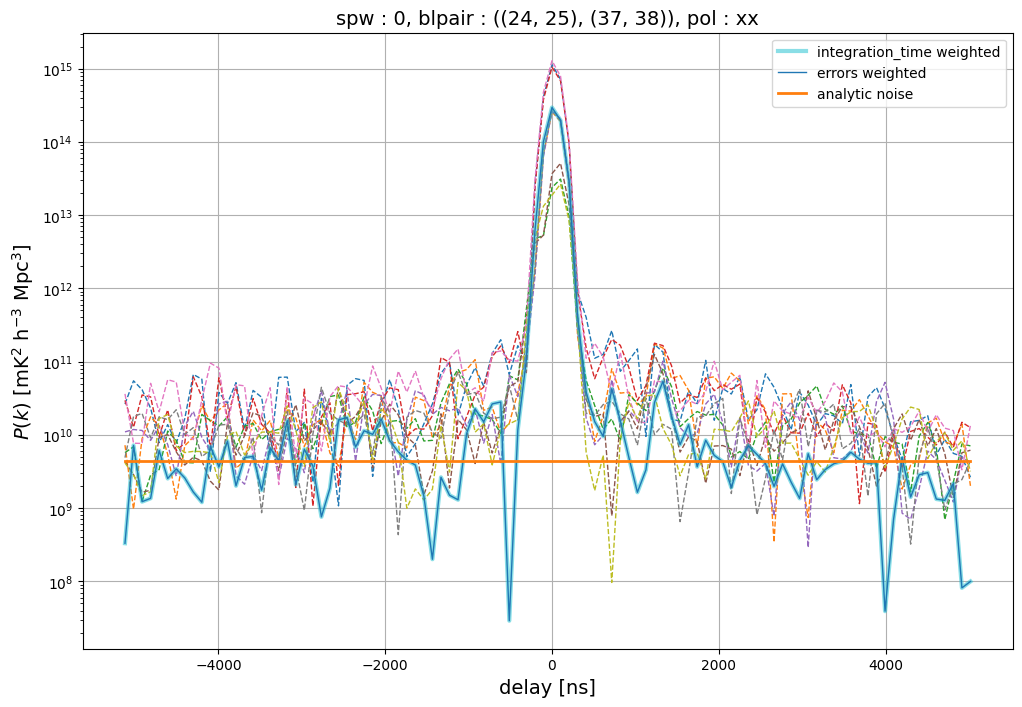

In [14]:
fig, ax = plt.subplots(figsize=(12, 8))

key = (0, ((24, 25), (37, 38)), "xx")
dlys = uvp.get_dlys(0).to_value(u.ns)
ps = np.abs(uvp.data_array[0][:, :, 0])
ps_avg_ints = np.abs(np.real(uvp_avg_ints_wgts.get_data(key)))
ps_avg_errors = np.abs(np.real(uvp_avg_error_wgts.get_data(key)))
blp = uvp.antnums_to_blpair(((24, 25), (37, 38)))
ax.plot(dlys, ps.T, lw=1, ls="--")
ax.plot(dlys, ps_avg_ints.T, lw=3, label="integration_time weighted", alpha=0.5)
ax.plot(dlys, ps_avg_errors.T, lw=1, label="errors weighted")
ax.plot(dlys, Pn[blp][0, :], lw=2, label="analytic noise")
ax.set_yscale("log")
ax.grid()
ax.set_xlabel("delay [ns]", fontsize=14)
ax.set_ylabel(r"$P(k)\ \rm [mK^2\ h^{-3}\ Mpc^3]$", fontsize=14)
ax.set_title("spw : {}, blpair : {}, pol : {}".format(*key), fontsize=14)
ax.legend(loc="best")

## Comparison on error field

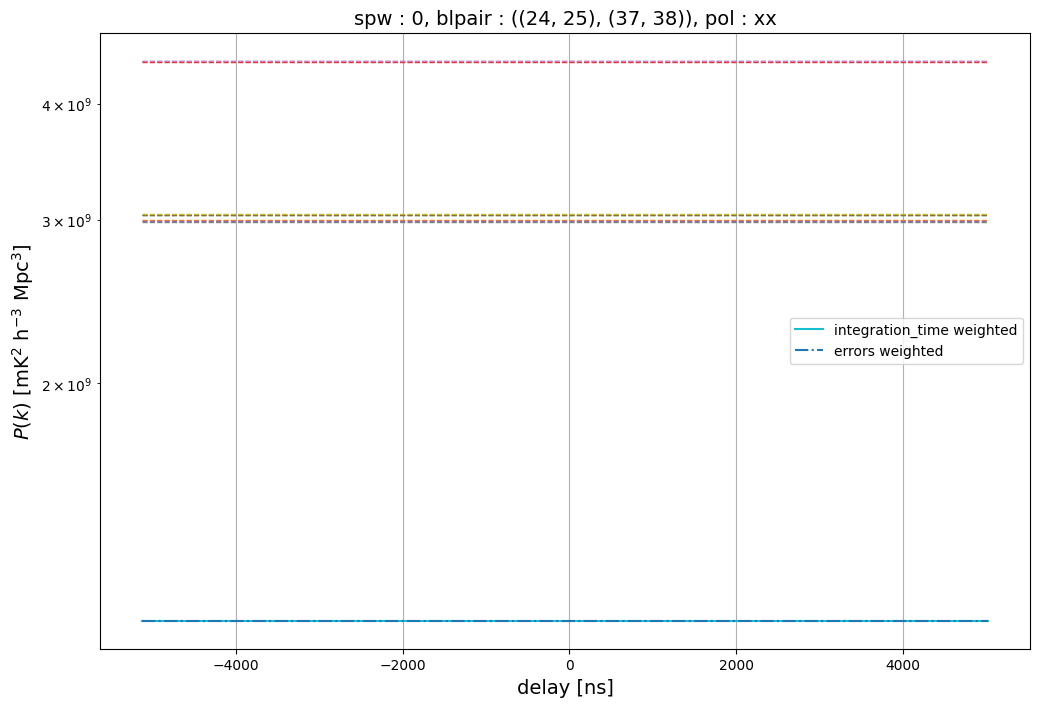

In [15]:
fig, ax = plt.subplots(figsize=(12, 8))

key = (0, ((24, 25), (37, 38)), "xx")
dlys = uvp.get_dlys(0).to_value(u.ns)
error = np.real(uvp.stats_array["noise"][0][:, :, 0])
error_avg_ints = np.real(uvp_avg_ints_wgts.get_stats("noise", key))
error_avg_errors = np.real(uvp_avg_error_wgts.get_stats("noise", key))

ax.plot(dlys, error.T, lw=1, ls="--")
ax.plot(dlys, error_avg_ints.T, label="integration_time weighted")
ax.plot(dlys, error_avg_errors.T, ls="-.", label="errors weighted")
ax.set_yscale("log")
ax.grid()
ax.set_xlabel("delay [ns]", fontsize=14)
ax.set_ylabel(r"$P(k)\ \rm [mK^2\ h^{-3}\ Mpc^3]$", fontsize=14)
ax.set_title("spw : {}, blpair : {}, pol : {}".format(*key), fontsize=14)
ax.set_yscale("log")
ax.legend(loc="best")

## Comparison on integration time

In [16]:
uvp.get_integrations(key)

array([393.33099972, 584.2536995 , 576.92973462])

In [17]:
uvp_avg_ints_wgts.get_integrations(key)

array([546.14991132])

In [18]:
uvp_avg_error_wgts.get_integrations(key)

array([546.14991132])

## Comparison on weights

In [19]:
uvp.get_wgts(key)[0, :, :]

array([[1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.

In [20]:
uvp_avg_ints_wgts.get_wgts(key)[0, :, :]

array([[1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.

In [21]:
uvp_avg_error_wgts.get_wgts(key)[0, :, :]

array([[1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.        , 1.        ],
       [1.